In [1]:
import sys, json, hashlib
from datetime import datetime, timezone
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src import prediccion as p
from src.descarga import leer, trm_reciente, md5
from src.validacion import errores_en_pesos, prueba_diebold_mariano
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_colwidth", 160)
FINAL, BASE = p.MODELO_FINAL, p.LINEA_BASE
T = lambda n, **kw: pd.read_csv(cfg.TABLAS / f"{n}.csv", **kw)

def es(x, decimales=2, signo=False):
    '''Escribe un número con punto de miles y coma decimal (formato colombiano).

    Parámetros
    ----------
    x : float
        Número.
    decimales : int, por defecto 2
        Decimales.
    signo : bool, por defecto False
        Antepone "+" a los positivos.

    Devuelve
    --------
    str
        El número formateado.
    '''
    t = f"{x:{'+' if signo else ''},.{decimales}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
print(f"Dataset: {len(datos):,} días ({datos['fecha'].min().date()} a {datos['fecha'].max().date()})")

Dataset: 5,401 días (2003-12-17 a 2026-09-26)


## 1. Limitaciones, con su evidencia y lo que se hizo para mitigarlas

In [2]:
t02b = T("tab02b_relleno", index_col=0)
t07c = T("tab07c_estabilidad_validacion_test", index_col=0)
t05g = T("tab05g_robustez_optuna", header=[0, 1], index_col=0).dropna(how="all")
t11 = T("tab11_boosting_vs_base", index_col=0)
t12a = T("tab12a_diferencial_por_regimen", index_col=0)
t15e = T("tab15e_cobertura_rango_80", index_col=0)["pct_dias_dentro_del_rango"]
from scipy import stats
rho = stats.spearmanr(t07c["puesto_validacion"], t07c["puesto_test"]).statistic
cambio_optuna = t05g["delta_rmse"].abs().max().max()
limitaciones = pd.DataFrame([
    ["Calidad y realismo de los datos",
     "Solo las variables acordadas en la Entrega 1 (sin VIX, otras monedas emergentes, puntos forward ni intervenciones del Banrep); el DXY viene de Yahoo Finance, no de una fuente oficial; las fuentes corrigen datos pasados; el Brent no tiene dato en los festivos de EE. UU.",
     f"El Brent repite el último valor en {t02b.loc['brent', 'pct_repetido']:.1f} % de los días (tab02b); fuentes en tab00",
     "Copia congelada con MD5; TRM verificada contra la Superintendencia Financiera; relleno solo con el último dato conocido (sin mirar el futuro)"],
    ["Supuestos de la simulación",
     "No hubo simulación: todos los datos son reales. La contracara es que solo existe una trayectoria histórica y el modelo no se probó en escenarios que no ocurrieron",
     "Informe de la Entrega 2, sección 7.1",
     "Validación en 5 periodos distintos (2007–2022) y test en 2022–2026, que incluyen crisis, choques petroleros y la pandemia"],
    ["Riesgo de sobreajuste",
     "El modelo con macro aprendió una regla de un solo episodio (diferencial alto = devaluación en 2008–2009); el techo de la forma en S y las reglas tras saltos grandes salen de pocos días; el método del artículo (árboles profundos, por defecto) sobreajusta",
     f"Días con diferencial > 7,8 pp: {int(t12a.iloc[0]['dias_dif_mayor_7_8'])} en el desarrollo, todos en 2008–2009 (tab12a); 63 días con saltos > 1,9 % (nb 09)",
     "Validación anidada, árboles de profundidad 2–6 con regularización, reglas fijadas antes de mirar, y modelo final sin variables macro"],
    ["Estabilidad",
     "Las diferencias entre modelos son de centavos y su orden cambia entre validación y test; los hiperparámetros elegidos cambian entre cortes",
     f"Correlación de Spearman entre los puestos de validación y de test: {es(rho)} (tab07c); la línea base pasa del puesto 6 al 1",
     f"Pruebas formales (Diebold-Mariano y bootstrap); robustez con Optuna (cambio máximo {es(cambio_optuna)} pesos, tab05g)"],
    ["Generalización",
     "Un solo periodo de test (2022–2026), agitado y ya abierto en la Entrega 2 y reutilizado para reportar en los notebooks 08 y 09; solo horizonte de un día; el rango del 80 % se queda corto con volatilidad alta",
     f"Rango fijo: {es(t15e['todos los días'], 0)} % de cobertura en el test, {es(t15e['volatilidad alta'], 0)} % con volatilidad alta (tab15e)",
     "La elección se hizo solo con validación; el test solo para reportar; semáforo de coherencia en la aplicación; M1 y M2 en este notebook"],
    ["Método",
     "Diebold-Mariano supone pérdidas sin cambios de régimen; se hicieron 30 comparaciones por corte (algunas pueden salir significativas por azar); el modelo final se mantuvo por la regla congelada pese al empate con la lineal",
     f"4 de 30 comparaciones por corte significativas, todas a favor de la base; p del mejor boosting = {es(t11.loc[FINAL, 'p_valor'])} (tab11)",
     "El empate se reporta con todas las letras; la regresión lineal se muestra al lado en la aplicación"],
], columns=["categoria", "limitacion", "evidencia", "mitigacion"]).set_index("categoria")
guardar_tabla(limitaciones, "tab16_limitaciones")
display(limitaciones)

,limitacion,evidencia,mitigacion
categoria,,,
Calidad y realismo de los datos,"Solo las variables acordadas en la Entrega 1 (sin VIX, otras monedas emergentes, puntos forward ni intervenciones del Banrep); el DXY viene de Yahoo Finance...",El Brent repite el último valor en 2.4 % de los días (tab02b); fuentes en tab00,Copia congelada con MD5; TRM verificada contra la Superintendencia Financiera; relleno solo con el último dato conocido (sin mirar el futuro)
Supuestos de la simulación,No hubo simulación: todos los datos son reales. La contracara es que solo existe una trayectoria histórica y el modelo no se probó en escenarios que no ocur...,"Informe de la Entrega 2, sección 7.1","Validación en 5 periodos distintos (2007–2022) y test en 2022–2026, que incluyen crisis, choques petroleros y la pandemia"
Riesgo de sobreajuste,El modelo con macro aprendió una regla de un solo episodio (diferencial alto = devaluación en 2008–2009); el techo de la forma en S y las reglas tras saltos...,"Días con diferencial > 7,8 pp: 151 en el desarrollo, todos en 2008–2009 (tab12a); 63 días con saltos > 1,9 % (nb 09)","Validación anidada, árboles de profundidad 2–6 con regularización, reglas fijadas antes de mirar, y modelo final sin variables macro"
Estabilidad,Las diferencias entre modelos son de centavos y su orden cambia entre validación y test; los hiperparámetros elegidos cambian entre cortes,"Correlación de Spearman entre los puestos de validación y de test: 0,32 (tab07c); la línea base pasa del puesto 6 al 1","Pruebas formales (Diebold-Mariano y bootstrap); robustez con Optuna (cambio máximo 0,22 pesos, tab05g)"
Generalización,"Un solo periodo de test (2022–2026), agitado y ya abierto en la Entrega 2 y reutilizado para reportar en los notebooks 08 y 09; solo horizonte de un día; el...","Rango fijo: 71 % de cobertura en el test, 67 % con volatilidad alta (tab15e)",La elección se hizo solo con validación; el test solo para reportar; semáforo de coherencia en la aplicación; M1 y M2 en este notebook
Método,Diebold-Mariano supone pérdidas sin cambios de régimen; se hicieron 30 comparaciones por corte (algunas pueden salir significativas por azar); el modelo fin...,"4 de 30 comparaciones por corte significativas, todas a favor de la base; p del mejor boosting = 0,32 (tab11)",El empate se reporta con todas las letras; la regresión lineal se muestra al lado en la aplicación


## 2. M1: un rango de predicción que se ensancha con la volatilidad
**Idea.** En lugar de un rango fijo (los percentiles 10 y 90 del error), se escala el error por la volatilidad reciente: z = error / volatilidad de las últimas *w* TRM. El rango del 80 % es la predicción ± los percentiles 10 y 90 de z multiplicados por la volatilidad del momento. Es una forma simple de **predicción conformal adaptativa**: se calibra con errores fuera de muestra y se evalúa en datos posteriores.

**Elección de la ventana *w*, solo con la validación.** Para cada ventana (10, 20, 40 y 60 TRM) se calibra con 4 de los 5 cortes de validación y se evalúa en el quinto; se elige la ventana cuya cobertura queda más cerca del 80 % en los tres niveles de volatilidad (el peor de los tres). El test no participa.

In [3]:
val = pd.read_csv(cfg.DATA_PROC / "predicciones_validacion.csv", parse_dates=["fecha"])
val = val[val["modelo"] == FINAL].copy()
val["e"] = val["y"] - val["yhat"]
vols = {w: datos.set_index("fecha")["r_trm_l1"].rolling(w).std() for w in (10, 20, 40, 60)}
filas = []
for w, vol in vols.items():
    x = val.assign(v=val["fecha"].map(vol))
    nivel = pd.qcut(x["v"], 3, labels=["baja", "media", "alta"])
    dentro = pd.Series(False, index=x.index)
    for k in range(1, 6):                                   # calibrar con 4 cortes, evaluar en el que queda fuera
        cal, ev = x[x["corte"] != k], x[x["corte"] == k]
        a, b = np.quantile(cal["e"] / cal["v"], [0.1, 0.9])
        dentro.loc[ev.index] = (ev["e"] >= a * ev["v"]) & (ev["e"] <= b * ev["v"])
    cob = 100 * dentro.groupby(nivel, observed=True).mean()
    filas.append({"ventana_trm": w, "cobertura_total": 100 * dentro.mean(), **{f"cobertura_vol_{n}": c for n, c in cob.items()},
                  "peor_desvio_de_80": (cob - 80).abs().max()})
dentro = pd.Series(False, index=val.index)
for k in range(1, 6):
    cal, ev = val[val["corte"] != k], val[val["corte"] == k]
    a, b = np.quantile(cal["e"], [0.1, 0.9])
    dentro.loc[ev.index] = (ev["e"] >= a) & (ev["e"] <= b)
filas.append({"ventana_trm": "fijo", "cobertura_total": 100 * dentro.mean()})
eleccion = pd.DataFrame(filas).set_index("ventana_trm")
W = int(eleccion.drop(index="fijo")["peor_desvio_de_80"].idxmin())
assert W == p.VENTANA_RANGO                                  # la aplicación usa la ventana elegida aquí
guardar_tabla(eleccion, "tab16a_eleccion_ventana_rango")
display(eleccion)
print(f"Ventana elegida con la validación: {W} TRM")

,cobertura_total,cobertura_vol_baja,cobertura_vol_media,cobertura_vol_alta,peor_desvio_de_80
ventana_trm,,,,,
10,80.1111,74.5833,80.5833,85.1667,5.4167
20,79.8611,76.3333,79.9167,83.3333,3.6667
40,80.0556,77.4167,79.9167,82.8333,2.8333
60,79.9722,77.2500,79.0000,83.6667,3.6667
fijo,79.6111,NaN,NaN,NaN,NaN


Ventana elegida con la validación: 40 TRM


In [4]:
pt = pd.read_csv(cfg.DATA_PROC / "predicciones_test.csv", parse_dates=["fecha"])
pt["e"] = pt["y"] - pt[FINAL]
pt["v"] = pt["fecha"].map(vols[W])
val["v"] = val["fecha"].map(vols[W])
q10, q90 = np.quantile(val["e"], [0.1, 0.9])                 # rango fijo, calibrado con toda la validación
z10, z90 = np.quantile(val["e"] / val["v"], [0.1, 0.9])      # rango adaptativo, calibrado con toda la validación
cortes_vol = datos.loc[datos["muestra"] == "desarrollo", "r_trm_l1"].rolling(20).std().quantile([1 / 3, 2 / 3]).to_numpy()
vol20 = pt["fecha"].map(datos.set_index("fecha")["r_trm_l1"].rolling(20).std())
nivel = pd.cut(vol20, [-1, *cortes_vol, 1], labels=["volatilidad baja", "volatilidad media", "volatilidad alta"])   # mismos grupos que el nb 09
bandas = {"Rango fijo": (np.full(len(pt), q10), np.full(len(pt), q90)), "Rango adaptativo": (z10 * pt["v"], z90 * pt["v"])}

def puntaje_intervalo(e, bajo, alto, alfa=0.2):
    '''Puntaje de intervalo (Winkler): ancho del rango más una penalidad cuando el valor real cae fuera.

    Parámetros
    ----------
    e : array-like
        Error real (real − predicho), en retorno.
    bajo, alto : array-like
        Límites del rango alrededor de la predicción, en retorno.
    alfa : float, por defecto 0.2
        1 − nivel del rango (0,2 para el 80 %).

    Devuelve
    --------
    np.ndarray
        Puntaje por día (menor es mejor), en la misma unidad que `e`.
    '''
    e, bajo, alto = map(np.asarray, (e, bajo, alto))
    return (alto - bajo) + (2 / alfa) * ((bajo - e) * (e < bajo) + (e - alto) * (e > alto))

filas = []
for nombre, (bajo, alto) in bandas.items():
    dentro = (pt["e"] >= bajo) & (pt["e"] <= alto)
    filas.append({"rango": nombre, "cobertura_total": 100 * dentro.mean(),
                  **{f"cobertura_{n}": c for n, c in (100 * dentro.groupby(nivel, observed=True).mean()).items()},
                  "ancho_mediano_pesos": float(np.median(pt["trm"] * (np.exp(alto) - np.exp(bajo)))),
                  "puntaje_intervalo_pesos": float(np.mean(pt["trm"] * puntaje_intervalo(pt["e"], bajo, alto)))})
m1 = pd.DataFrame(filas).set_index("rango")
guardar_tabla(m1, "tab16b_rango_adaptativo_test")
display(m1)

,cobertura_total,cobertura_volatilidad baja,cobertura_volatilidad media,cobertura_volatilidad alta,ancho_mediano_pesos,puntaje_intervalo_pesos
rango,,,,,,
Rango fijo,71.2963,82.3529,78.4530,66.5667,69.9550,129.0644
Rango adaptativo,79.5370,72.5490,79.2818,80.2099,81.0991,124.0326


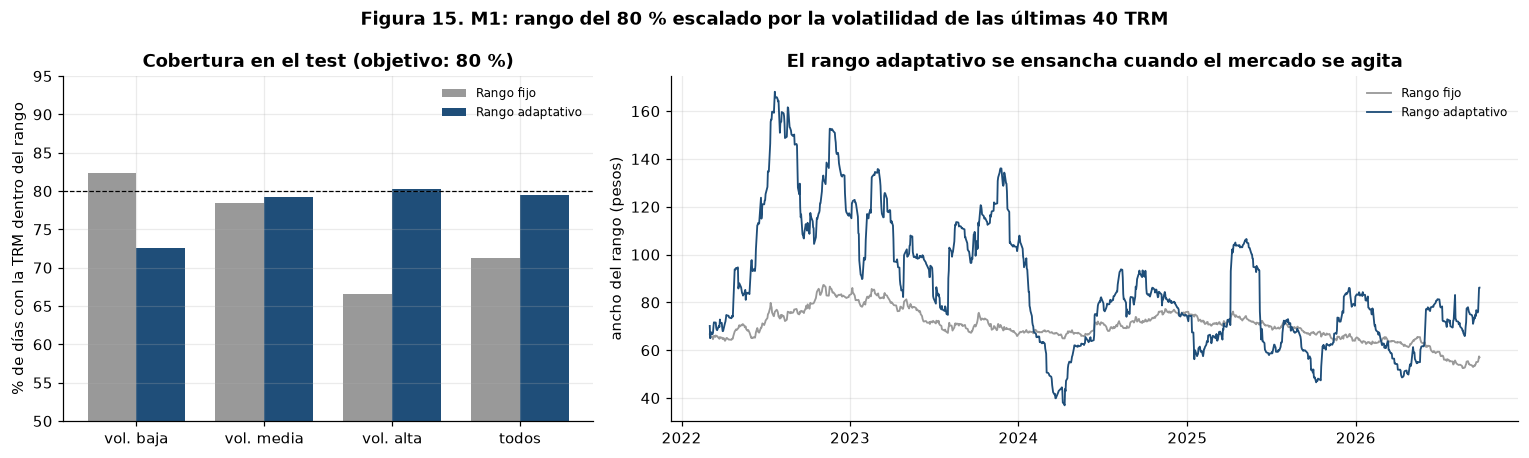

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
eje = ejes[0]
grupos = ["cobertura_volatilidad baja", "cobertura_volatilidad media", "cobertura_volatilidad alta", "cobertura_total"]
x = np.arange(len(grupos))
for j, (nombre, c) in enumerate(zip(m1.index, ["0.6", COLORES[0]])):
    eje.bar(x + (j - 0.5) * 0.38, m1.loc[nombre, grupos], 0.38, color=c, label=nombre)
eje.axhline(80, color="k", lw=0.8, ls="--")
eje.set(xticks=x, xticklabels=["vol. baja", "vol. media", "vol. alta", "todos"], ylim=(50, 95),
        ylabel="% de días con la TRM dentro del rango", title="Cobertura en el test (objetivo: 80 %)")
eje.legend(frameon=False, fontsize=8)
eje = ejes[1]
for nombre, (bajo, alto), c in [("Rango fijo", bandas["Rango fijo"], "0.6"), ("Rango adaptativo", bandas["Rango adaptativo"], COLORES[0])]:
    eje.plot(pt["fecha"], pt["trm"] * (np.exp(alto) - np.exp(bajo)), color=c, lw=1.2, label=nombre)
eje.set(ylabel="ancho del rango (pesos)", title="El rango adaptativo se ensancha cuando el mercado se agita")
eje.legend(frameon=False, fontsize=8)
fig.suptitle(f"Figura 15. M1: rango del 80 % escalado por la volatilidad de las últimas {W} TRM", fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig15_rango_adaptativo"); plt.show()

## 3. M2: evaluación con datos nuevos (monitoreo)
Las TRM publicadas después del 26/09/2026 no estaban en ningún dato de entrenamiento ni de evaluación. Se descargan una vez de datos.gov.co y se congelan con MD5 (si ya existen, se verifica la huella y no se vuelven a descargar). Se evalúa el modelo **que usa la aplicación** (reentrenado hasta el 26/09/2026), con la regresión lineal y "mañana igual que hoy" como referencias, y el rango adaptativo de la aplicación.

In [6]:
CARPETA = cfg.DATA_RAW / "monitoreo"
ARCHIVO, META = CARPETA / "trm_reciente_datosgov.csv", CARPETA / "metadatos.json"
if ARCHIVO.exists() and META.exists():
    meta = json.loads(META.read_text(encoding="utf-8"))
    assert md5(ARCHIVO) == meta["md5"], "la copia congelada del monitoreo fue modificada"
else:
    CARPETA.mkdir(parents=True, exist_ok=True)
    trm_reciente(120).to_csv(ARCHIVO, index=False, date_format="%Y-%m-%d")
    nueva = pd.read_csv(ARCHIVO, parse_dates=["fecha"])
    meta = {"fuente": "datos.gov.co, conjunto 32sa-8pi3 (Superintendencia Financiera)", "descargado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "md5": md5(ARCHIVO), "filas": len(nueva), "fecha_min": str(nueva["fecha"].min().date()), "fecha_max": str(nueva["fecha"].max().date())}
    META.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
nueva = pd.read_csv(ARCHIVO, parse_dates=["fecha", "vigencia_hasta"])
copia = leer("trm_vigencias")
comun = nueva.merge(copia, on="fecha", suffixes=("_nueva", "_copia"))
assert (comun["valor_nueva"] == comun["valor_copia"]).all()       # los días comunes coinciden con la copia del proyecto
serie = pd.concat([copia, nueva[nueva["fecha"] > copia["fecha"].max()]], ignore_index=True)
assert serie["fecha"].is_monotonic_increasing and not serie["fecha"].duplicated().any()
ultimo_entrenamiento = p.datos_entrenamiento()["fecha"].max()      # 26/09/2026: su objetivo usa la TRM siguiente
print(meta)
print(f"Días comunes con la copia del proyecto: {len(comun)} (idénticos). Último día de entrenamiento del modelo de la app: {ultimo_entrenamiento.date()}")

{'fuente': 'datos.gov.co, conjunto 32sa-8pi3 (Superintendencia Financiera)', 'descargado_utc': '2026-11-10T19:29:59+00:00', 'md5': 'c9ab7ecf44da3593aeb405b4f82d3a3c', 'filas': 120, 'fecha_min': '2026-05-08', 'fecha_max': '2026-11-10'}
Días comunes con la copia del proyecto: 93 (idénticos). Último día de entrenamiento del modelo de la app: 2026-09-26


In [7]:
modelos = p.cargar_modelos()
error = p.errores_historicos()
referencia = p.referencia_entrenamiento()
posiciones = serie.index[serie["fecha"] > ultimo_entrenamiento]
filas = []
for i in posiciones[:-1]:                                          # cada día con TRM siguiente conocida
    historia = serie.loc[:i]
    pred = p.predecir(modelos, historia["valor"].tail(60), error)
    coh = p.chequear_coherencia(historia.tail(60), referencia, historia["fecha"].iloc[-1])
    hoy, real = serie.loc[i, "valor"], serie.loc[i + 1, "valor"]
    f = pred.loc[FINAL]
    filas.append({"fecha": serie.loc[i, "fecha"], "trm_hoy": hoy, "trm_siguiente": real,
                  "pred_modelo": f["trm_manana"], "pred_lineal": pred.loc[BASE, "trm_manana"],
                  "min_80": f["trm_min_80"], "max_80": f["trm_max_80"],
                  "error_modelo": real - f["trm_manana"], "error_lineal": real - pred.loc[BASE, "trm_manana"], "error_ingenuo": real - hoy,
                  "alertas": ", ".join(c for c, s in coh["estado"].items() if s != "ok") or "ninguna"})
mon = pd.DataFrame(filas)
guardar_tabla(mon.set_index("fecha"), "tab16c_monitoreo_diario")
mov = mon[mon["trm_siguiente"] != mon["trm_hoy"]]
resumen_m2 = pd.DataFrame({
    nombre: {"dias": len(mon), "mae_pesos": mon[c].abs().mean(), "rmse_pesos": np.sqrt((mon[c] ** 2).mean()),
             "acierto_direccion_pct": 100 * (np.sign(mov[c.replace("error", "pred") if c != "error_ingenuo" else "trm_hoy"] - mov["trm_hoy"])
                                             == np.sign(mov["trm_siguiente"] - mov["trm_hoy"])).mean() if c != "error_ingenuo" else np.nan}
    for nombre, c in [("Modelo final (app)", "error_modelo"), ("Regresión lineal", "error_lineal"), ("Mañana igual que hoy", "error_ingenuo")]}).T
cobertura_nueva = 100 * ((mon["trm_siguiente"] >= mon["min_80"]) & (mon["trm_siguiente"] <= mon["max_80"])).mean()
dm_nuevo = prueba_diebold_mariano(mon["error_modelo"], mon["error_ingenuo"], rezagos=2)
dm_lin = prueba_diebold_mariano(mon["error_modelo"], mon["error_lineal"], rezagos=2)
resumen_m2["cobertura_rango_80_pct"] = [cobertura_nueva, np.nan, np.nan]
resumen_m2["p_dm_vs_modelo_final"] = [np.nan, dm_lin["p_valor"], dm_nuevo["p_valor"]]
guardar_tabla(resumen_m2, "tab16d_monitoreo_resumen")
display(resumen_m2)
print(f"Periodo: {mon['fecha'].min().date()} a {mon['fecha'].max().date()} ({len(mon)} predicciones). "
      f"Días con alguna alerta del semáforo: {(mon['alertas'] != 'ninguna').sum()} ({', '.join(sorted(set(a for s in mon['alertas'] for a in s.split(', ') if a != 'ninguna'))) or 'ninguna'}).")

,dias,mae_pesos,rmse_pesos,acierto_direccion_pct,cobertura_rango_80_pct,p_dm_vs_modelo_final
Modelo final (app),28.0000,19.7440,23.4616,57.1429,92.8571,NaN
Regresión lineal,28.0000,19.6256,23.4721,57.1429,NaN,0.9635
Mañana igual que hoy,28.0000,18.6075,23.5265,NaN,NaN,0.9340


Periodo: 2026-09-29 a 2026-11-07 (28 predicciones). Días con alguna alerta del semáforo: 18 (regimen_volatilidad).


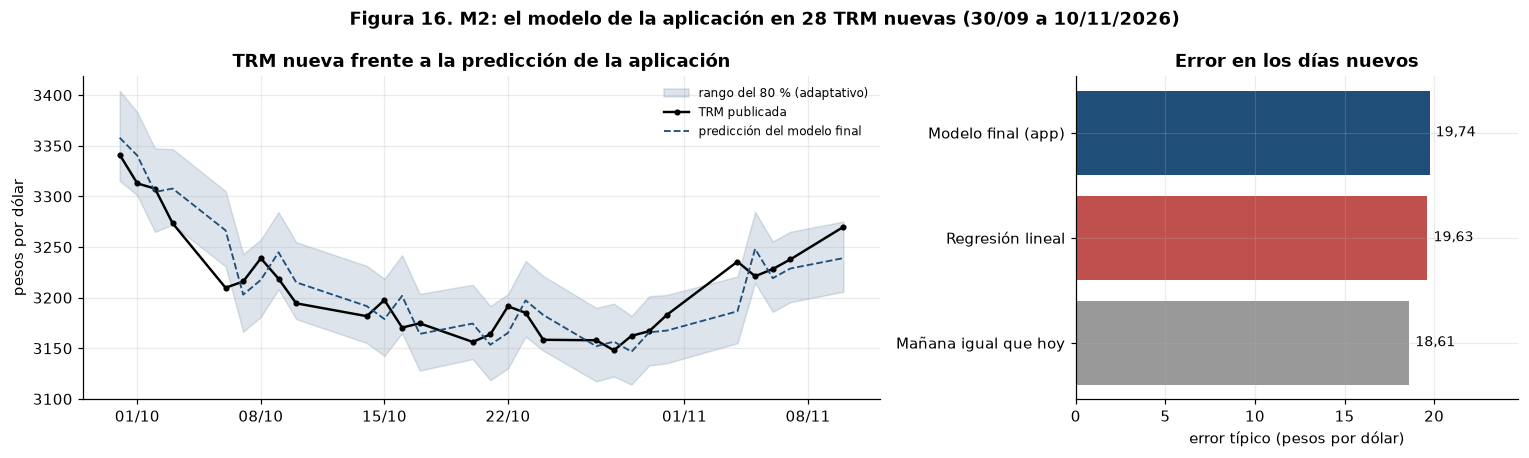

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.8, 1]})
eje = ejes[0]
fechas_sig = pd.to_datetime(serie.loc[posiciones[1:], "fecha"]).reset_index(drop=True)
eje.fill_between(fechas_sig, mon["min_80"], mon["max_80"], color=COLORES[0], alpha=0.15, label="rango del 80 % (adaptativo)")
eje.plot(fechas_sig, mon["trm_siguiente"], color="k", lw=1.6, marker="o", ms=3, label="TRM publicada")
eje.plot(fechas_sig, mon["pred_modelo"], color=COLORES[0], lw=1.2, ls="--", label="predicción del modelo final")
eje.set(ylabel="pesos por dólar", title="TRM nueva frente a la predicción de la aplicación")
import matplotlib.dates as mdates
eje.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
eje.legend(frameon=False, fontsize=8)
eje = ejes[1]
mae = resumen_m2["mae_pesos"]
eje.barh(range(len(mae))[::-1], mae.to_numpy(), color=[COLORES[0], COLORES[1], "0.6"])
for yy, v in zip(range(len(mae))[::-1], mae.to_numpy()):
    eje.annotate(es(v), (v, yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
eje.set(yticks=range(len(mae))[::-1], yticklabels=mae.index, xlabel="error típico (pesos por dólar)", title="Error en los días nuevos")
eje.set_xlim(0, mae.max() * 1.25)
fig.suptitle(f"Figura 16. M2: el modelo de la aplicación en {len(mon)} TRM nuevas ({fechas_sig.iloc[0]:%d/%m} a {fechas_sig.iloc[-1]:%d/%m/%Y})",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig16_monitoreo_datos_nuevos"); plt.show()

## 4. Mejoras propuestas y proyección hacia Deep Learning y MLOps

In [9]:
mejoras = pd.DataFrame([
    ["M1", "Rango del 80 % que se ensancha con la volatilidad (conformal adaptativo)", "Cobertura del rango fijo: 67 % con volatilidad alta", "Probada (sección 2) y llevada a la aplicación"],
    ["M2", "Monitoreo con datos nuevos", "El test ya se había abierto y reutilizado", "Probada (sección 3); repetirla periódicamente"],
    ["M3", "Integración continua: pruebas y verificador de documentación en cada cambio del repositorio", "Reproducibilidad a futuro (p. ej., el cambio de versión de xgboost alteró resultados)", "Propuesta (requiere un servicio externo, p. ej. GitHub Actions)"],
    ["M4", "Variables con información del mismo día: cierre del mercado colombiano, VIX, peso mexicano y otras monedas emergentes, puntos forward, intervenciones del Banrep", "Variables limitadas al contrato de la Entrega 1", "Propuesta (cambia la pregunta)"],
    ["M5", "Predecir el tamaño del movimiento (volatilidad, ln|r|) como problema complementario", "La dirección no es predecible; el riesgo sí (memoria de 0,22; R² fuera de muestra ≈ 0,14 en una exploración)", "Propuesta"],
    ["M6", "Horizontes de semanas o meses e indicadores de régimen (inflación, ciclo de tasas)", "Solo horizonte de un día; régimen del diferencial", "Propuesta"],
], columns=["id", "mejora", "responde_a", "estado"]).set_index("id")
deep = pd.DataFrame([
    ["Redes recurrentes (LSTM, GRU) y convolucionales temporales", "Aprenden patrones en secuencias largas y multivariadas sin definir rezagos a mano"],
    ["Temporal Fusion Transformer", "Combina variables pasadas y conocidas a futuro; su atención es interpretable y entrega intervalos"],
    ["Pronóstico probabilístico (p. ej. DeepAR)", "Estima toda la distribución de la TRM de mañana: conecta con M1"],
    ["Expectativa honesta", "Con la señal actual (≈ 3 % explicable a un día), más complejidad no tiene qué aprender; tendría sentido con datos intradía o más variables (M4) y se evaluaría con el mismo protocolo (validación anidada y Diebold-Mariano frente a la lineal)"],
], columns=["tecnica", "por_que_y_cuando"]).set_index("tecnica")
mlops = pd.DataFrame([
    ["Datos versionados", "Copias congeladas con MD5 (incluido el monitoreo)", "Descarga diaria programada con validación automática"],
    ["Modelos versionados", "Huellas y predicciones de control; ficha del modelo", "Registro de modelos (p. ej. MLflow) con métricas por versión"],
    ["Validación de datos en uso", "Semáforo de coherencia en la aplicación", "Alertas automáticas y medidas de deriva (p. ej. PSI de las variables)"],
    ["Monitoreo del desempeño", "M2: error en los días nuevos y cobertura del rango", "Tablero diario del error frente al rango esperado"],
    ["Reentrenamiento", "Una vez, con 2003–2026", "Política mensual: aceptar el nuevo modelo solo si no es peor (Diebold-Mariano) que el actual"],
    ["Pruebas", "14 pruebas automáticas + verificador de documentación", "M3: ejecutarlas en cada cambio (integración continua)"],
    ["Despliegue", "Aplicación en Streamlit Community Cloud", "Contenedor para no depender de la plataforma"],
], columns=["pieza", "ya_existe", "siguiente_paso"]).set_index("pieza")
for nombre, t in [("tab16e_mejoras", mejoras), ("tab16f_deep_learning", deep), ("tab16g_mlops", mlops)]:
    guardar_tabla(t, nombre); display(t)

,mejora,responde_a,estado
id,,,
M1,Rango del 80 % que se ensancha con la volatilidad (conformal adaptativo),Cobertura del rango fijo: 67 % con volatilidad alta,Probada (sección 2) y llevada a la aplicación
M2,Monitoreo con datos nuevos,El test ya se había abierto y reutilizado,Probada (sección 3); repetirla periódicamente
M3,Integración continua: pruebas y verificador de documentación en cada cambio del repositorio,"Reproducibilidad a futuro (p. ej., el cambio de versión de xgboost alteró resultados)","Propuesta (requiere un servicio externo, p. ej. GitHub Actions)"
M4,"Variables con información del mismo día: cierre del mercado colombiano, VIX, peso mexicano y otras monedas emergentes, puntos forward, intervenciones del Ba...",Variables limitadas al contrato de la Entrega 1,Propuesta (cambia la pregunta)
M5,"Predecir el tamaño del movimiento (volatilidad, ln|r|) como problema complementario","La dirección no es predecible; el riesgo sí (memoria de 0,22; R² fuera de muestra ≈ 0,14 en una exploración)",Propuesta
M6,"Horizontes de semanas o meses e indicadores de régimen (inflación, ciclo de tasas)",Solo horizonte de un día; régimen del diferencial,Propuesta


,por_que_y_cuando
tecnica,
"Redes recurrentes (LSTM, GRU) y convolucionales temporales",Aprenden patrones en secuencias largas y multivariadas sin definir rezagos a mano
Temporal Fusion Transformer,Combina variables pasadas y conocidas a futuro; su atención es interpretable y entrega intervalos
Pronóstico probabilístico (p. ej. DeepAR),Estima toda la distribución de la TRM de mañana: conecta con M1
Expectativa honesta,"Con la señal actual (≈ 3 % explicable a un día), más complejidad no tiene qué aprender; tendría sentido con datos intradía o más variables (M4) y se evaluar..."


,ya_existe,siguiente_paso
pieza,,
Datos versionados,Copias congeladas con MD5 (incluido el monitoreo),Descarga diaria programada con validación automática
Modelos versionados,Huellas y predicciones de control; ficha del modelo,Registro de modelos (p. ej. MLflow) con métricas por versión
Validación de datos en uso,Semáforo de coherencia en la aplicación,Alertas automáticas y medidas de deriva (p. ej. PSI de las variables)
Monitoreo del desempeño,M2: error en los días nuevos y cobertura del rango,Tablero diario del error frente al rango esperado
Reentrenamiento,"Una vez, con 2003–2026",Política mensual: aceptar el nuevo modelo solo si no es peor (Diebold-Mariano) que el actual
Pruebas,14 pruebas automáticas + verificador de documentación,M3: ejecutarlas en cada cambio (integración continua)
Despliegue,Aplicación en Streamlit Community Cloud,Contenedor para no depender de la plataforma


## Lectura
**1. Limitaciones (Tabla 16).** Las seis categorías tienen evidencia concreta en el proyecto y una mitigación. Las dos más importantes son la **generalización** (un solo test, ya abierto y reutilizado; el rango fijo se queda corto con volatilidad alta) y la **estabilidad** (diferencias de centavos; el orden de los modelos cambia entre validación y test). **No hubo simulación:** los datos son reales; la contracara es que solo existe una historia y no se probaron escenarios que no ocurrieron.

**2. M1 funciona: el rango adaptativo cumple el 80 % (Tabla 16b, Figura 15).**
- La ventana de 40 TRM se eligió **solo con la validación** (la de cobertura más pareja entre niveles de volatilidad, Tabla 16a).
- En el test, el rango fijo contenía la TRM real el **71 %** de los días (67 % con volatilidad alta); el adaptativo, el **80 %** (80 % con volatilidad alta y 79 % con media).
- Es más ancho en promedio (81 frente a 70 pesos), pero se gana en el puntaje de intervalo, que premia ser estrecho y penaliza fallar (124 frente a 129 pesos): el ancho extra se usa cuando hace falta (unos 165 pesos en 2022) y se reduce en calma (unos 40 pesos en 2024).
- **Límite:** en los pocos días de volatilidad baja del test (51) el rango queda algo estrecho (73 %).
- **Se llevó a la aplicación:** `src/prediccion.py` lo calcula con todos los errores fuera de muestra (validación y test) y la app lo muestra; con menos de 41 TRM usa el rango fijo. Tres pruebas nuevas lo verifican.

**3. M2: en las 28 TRM nuevas el modelo se comporta como se esperaba (Tabla 16d, Figura 16).**
- Error típico de **19,7 pesos** (la lineal 19,6; "mañana igual que hoy" 18,6): las tres referencias empatan; con 28 días ninguna diferencia se puede distinguir (Diebold-Mariano p = 0,93 frente a "mañana igual que hoy"). No hay señales de deterioro: el error es menor que el del test (27 pesos) porque los movimientos de estas semanas fueron menores que los de 2022–2023, aunque la volatilidad siguió en el tercio más alto de la historia.
- El rango adaptativo contuvo la TRM real en **26 de 28 días (93 %)**: conservador, sin fallar en los días de mayor movimiento.
- El semáforo marcó volatilidad alta en 18 de los 28 días (las semanas posteriores al choque petrolero de 2026), y ningún otro chequeo falló: los datos nuevos son coherentes con los de entrenamiento.
- Es la única evaluación realmente nueva del proyecto, y es corta: sirve como **monitoreo**, no como prueba definitiva. Repetirla cada mes es el primer paso de MLOps.

**4. Proyección (Tablas 16e–g).** Cada mejora responde a una limitación: M1 y M2 probadas; integración continua, variables del mismo día, predecir la volatilidad y horizontes largos, propuestas. En **Deep Learning**, los modelos de secuencias (LSTM, Temporal Fusion Transformer) y el pronóstico probabilístico (DeepAR) son el paso natural, con una expectativa honesta: con ~3 % de señal a un día, más complejidad no tiene qué aprender; tendrían sentido con datos intradía o más variables, evaluados con el mismo protocolo frente a la lineal. En **MLOps**, el proyecto ya tiene datos y modelos versionados, validación de datos en uso, pruebas automáticas y despliegue; siguen la descarga programada, el registro de modelos, las alertas de deriva, el reentrenamiento mensual con prueba de no inferioridad y la integración continua.

**En una frase (para el informe):** *las limitaciones más serias son que el test es uno solo y ya se usó, y que el rango fijo se quedaba corto con el mercado agitado; la segunda se corrigió con un rango que se ensancha con la volatilidad (cobertura del 71 % al 80 %), y la primera se atenuó evaluando el modelo en 28 TRM nuevas, donde se comportó como se esperaba.*